# Flipped condition grid — days in columns, metaclone x arm in rows

The authors asked for a flipped version of the MC0 / MC3 / MC7 condition grids: **columns** Day 14 and Day 27,
**rows** MC0 [WT, Dnmt3a, Npm1c], MC3 [WT, Dnmt3a, Npm1c], MC7 [WT, Dnmt3a, Npm1c].
The three separate grids become one panel with no colour bar; the shared density key is drawn as its own
**horizontal** colour-bar plot (The authors: "Just plot the color bar").

Display only. The setup cells below are taken unchanged (except the output directory, kernel name and
execution command) from the audited grid notebook
`analysis_workspace/singh/singh_figure2b_grid_layout_20260911/0001_figure2b_grid_layout.ipynb`, which produced
the current condition grids: same cell registry, UMAP, fixed bandwidth, common density scale, marker
calibration and sparse/empty handling. Only the layout changes. No new expression access, embedding,
assignment, test or normalisation.

Environment **chronoclone**, `/path/to/ChronoClone/.runtime/chronoclone`
(-> `/path/to/ChronoClone/.runtime/chronoclone`), kernel **chronoclone-paper**.
Versions and the execution command are printed by the first cell.


In [1]:

from pathlib import Path
import sys,platform,json,hashlib,datetime,warnings
import numpy as np
import pandas as pd
import h5py,scipy,matplotlib
from scipy.ndimage import gaussian_filter,map_coordinates
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from IPython.display import display
from PIL import Image
ROOT=Path('/path/to/ChronoClone')
OUT=ROOT/'reference_workspace/Figure/singh_condition_grid_flipped_20261021'
ENV=Path('/path/to/ChronoClone/.runtime/chronoclone')
assert Path(sys.executable).resolve().parent.parent==ENV.resolve()
for directory in ['panels','tables','reports']:(OUT/directory).mkdir(parents=True,exist_ok=True)
execution_command='JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper /path/to/ChronoClone/reference_workspace/Figure/singh_condition_grid_flipped_20261021/figure_6c_condition_grid_flipped.ipynb'
environment={'name':'chronoclone','path':str(ENV),'manager':'existing Conda-managed environment; no mutation','kernel':'chronoclone-paper',
             'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,
             'h5py':h5py.__version__,'matplotlib':matplotlib.__version__,'execution_command':execution_command}
display(environment)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':16,'axes.labelsize':16,'svg.fonttype':'none',
                     'savefig.facecolor':'white','figure.facecolor':'white','svg.hashsalt':'singh_weinreb_style_20260911'})
def sha256(path):
    digest=hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):digest.update(block)
    return digest.hexdigest()
CELL_SOURCE=ROOT/'analysis_workspace/singh/singh_reference_response_20260911/dynamics/tables/cells_resolved.csv'
MAP_SOURCE=ROOT/'data/processed/singh_strack/adata_valid_keep_all.h5ad'
PALETTE_SOURCE=ROOT/'analysis_workspace/singh/figure3_original_singh_landscape_20260811/tables/figure3_original_singh_clone_trajectory_umap_metaclone_label_positions.csv'
source_manifest=pd.DataFrame([{'source':str(p.relative_to(ROOT)),'bytes':p.stat().st_size,'sha256':sha256(p)} for p in [CELL_SOURCE,MAP_SOURCE,PALETTE_SOURCE]])
source_manifest.to_csv(OUT/'tables/source_manifest.csv',index=False)
display(source_manifest)

AUTHOR_NOTEBOOK=ROOT/'reference_workspace/notebooks/Figure2_klein_pace.ipynb'
AUTHOR_SVG=ROOT/'reference_workspace/Figure/fig2/panels/panel_2i_density_all_mc_flipped.svg'
OLD_ATLAS=ROOT/'analysis_workspace/singh/singh_landscape_expansion_20260911/atlas'
REFERENCE_AXES_WIDTH_PT=31 * 72 * (0.995-0.04) / (20+19*0.02)
assert abs(REFERENCE_AXES_WIDTH_PT-104.590775)<1e-6
style_sources=pd.DataFrame([{'source':str(p.relative_to(ROOT)),'bytes':p.stat().st_size,'sha256':sha256(p)}
    for p in [AUTHOR_NOTEBOOK,AUTHOR_SVG,OLD_ATLAS/'0001_metaclone_spatial_atlas.ipynb',OUT/'build_notebook.py']])
style_sources.to_csv(OUT/'tables/style_source_manifest.csv',index=False)
display(style_sources)
print('Reference axes width (pt):',REFERENCE_AXES_WIDTH_PT)


{'name': 'chronoclone',
 'path': '/path/to/ChronoClone/.runtime/chronoclone',
 'manager': 'existing Conda-managed environment; no mutation',
 'kernel': 'chronoclone-paper',
 'python': '3.11.15',
 'numpy': '2.4.6',
 'pandas': '2.3.3',
 'scipy': '1.17.1',
 'h5py': '3.16.0',
 'matplotlib': '3.11.0',
 'execution_command': 'JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper /path/to/ChronoClone/reference_workspace/Figure/singh_condition_grid_flipped_20261021/figure_6c_condition_grid_flipped.ipynb'}

,source,bytes,sha256
0,analysis_workspace/singh/singh_reference_response_2...,3949086,1c6107fb429938c2c0ecdf2ef0119a606c3df10caea1c5...
1,data/processed/singh_strack/adata_valid_keep_a...,2859494374,9822997506ef9b2294c6c467cdb0fb6022c7a0c0e132f3...
2,analysis_workspace/singh/figure3_original_singh_lan...,3430,df1b27dc2c3440de24f4c345764d2da73a2bece5a461d9...


,source,bytes,sha256
0,reference_workspace/notebooks/Figure2_klein_pace.ipynb,5483967,8f653511b3de1c38f044438f6dff00970cbecf47f6e619...
1,reference_workspace/Figure/fig2/panels/panel_2i_den...,839150,147ddac7c553fc66fc6fdbfe3ed41312939cb038408ca7...
2,analysis_workspace/singh/singh_landscape_expansion_...,9320663,51eca4e3e3bdfd1596811cdf92b5a9d8956c82a2040cd3...
3,reference_workspace/Figure/singh_condition_grid_fli...,9553,e9c4153c4c3d16ff7e6e98845103f530926390a6833757...


Reference axes width (pt): 104.59077526987242


In [2]:

# Read only the cell registry, HDF5 observation index and stored embedding. Do not access X/raw/layers.
cells=pd.read_csv(CELL_SOURCE,keep_default_na=False)
assert cells.cell_id.is_unique and cells.clone.ne('').all() and cells.clone_resolved.eq(True).all()
with h5py.File(MAP_SOURCE,'r') as source:
    index_key=source['obs'].attrs['_index']
    if isinstance(index_key,bytes):index_key=index_key.decode()
    full_ids=pd.Index(source['obs'][index_key].asstr()[:],name='cell_id')
    full_umap=np.asarray(source['obsm']['X_umap'][:,:2],dtype=np.float64)
assert full_ids.is_unique and len(full_ids)==96662 and full_umap.shape==(len(full_ids),2)
assert np.isfinite(full_umap).all()
positions=full_ids.get_indexer(cells.cell_id)
assert (positions>=0).all()
cells['umap1']=full_umap[positions,0];cells['umap2']=full_umap[positions,1]
assert np.array_equal(cells[['umap1','umap2']].to_numpy(),full_umap[positions])
MC_IDS=sorted(cells.mc.astype(int).unique().tolist())
assert len(MC_IDS)==17
SNAPSHOTS=[('WT','D7'),('WT','D14'),('WT','D27'),('Npm1c','D14'),('Npm1c','D27'),('Dnmt3a','D14'),('Dnmt3a','D27')]
assert set(zip(cells.arm,cells.day))==set(SNAPSHOTS)
assert cells.groupby('clone').mc.nunique().max()==1
assert not cells[['umap1','umap2']].isna().any().any()
cells[['cell_id','mc','arm','day','clone','umap1','umap2']].to_csv(OUT/'tables/atlas_cell_coordinates.csv.gz',index=False)
BANDWIDTH=0.4
GRID_SIZE=256
PLOT_XLIM=(full_umap[:,0].min()-0.4,full_umap[:,0].max()+0.4)
PLOT_YLIM=(full_umap[:,1].min()-0.4,full_umap[:,1].max()+0.4)
X_EDGES=np.linspace(full_umap[:,0].min()-4*BANDWIDTH,full_umap[:,0].max()+4*BANDWIDTH,GRID_SIZE+1)
Y_EDGES=np.linspace(full_umap[:,1].min()-4*BANDWIDTH,full_umap[:,1].max()+4*BANDWIDTH,GRID_SIZE+1)
DX=float(X_EDGES[1]-X_EDGES[0]);DY=float(Y_EDGES[1]-Y_EDGES[0])
X_CENTERS=(X_EDGES[:-1]+X_EDGES[1:])/2;Y_CENTERS=(Y_EDGES[:-1]+Y_EDGES[1:])/2
MIN_DENSITY_CELLS=20;MIN_DENSITY_FAMILIES=3
SPARSE_COLOR='#234B6C'
MC_LABEL_COLORS={0:'#f77189',1:'#f8763b',2:'#d28e32',3:'#b79932',4:'#9ea231',5:'#7caa31',6:'#31b345',7:'#34b081',9:'#35ae9a',10:'#36acad',11:'#38aac1',12:'#3aa6dd',13:'#7699f4',15:'#b087f4',16:'#df6df4',17:'#f563d8',19:'#f66ab2'}
assert set(MC_LABEL_COLORS)==set(MC_IDS)
palette_source=pd.read_csv(PALETTE_SOURCE)
assert dict(zip(palette_source.metaclone.astype(int),palette_source.label_color))==MC_LABEL_COLORS
display(palette_source[['metaclone','label_color']])
design={'fullmap_cells':len(full_ids),'registry_cells':len(cells),'unique_families':cells.clone.nunique(),
        'metaclones':MC_IDS,'snapshots':SNAPSHOTS,'expected_maps':len(MC_IDS)*len(SNAPSHOTS),
        'plot_xlim':PLOT_XLIM,'plot_ylim':PLOT_YLIM,'bandwidth_umap_units':BANDWIDTH,
        'grid_size':[GRID_SIZE,GRID_SIZE],'grid_dx':DX,'grid_dy':DY,
        'density_min_cells':MIN_DENSITY_CELLS,'density_min_families':MIN_DENSITY_FAMILIES,
        'density_weighting':'each observed cell equally weighted within its MC/arm/day snapshot',
        'source_coordinate_identity':'exact float64 values from original X_umap in source row order',
        'mc_label_palette':MC_LABEL_COLORS,'font_family':'DejaVu Sans',
        'expression_matrix_accessed':False,'umap_refitted':False,'background_rasterized_only':True}
(OUT/'reports/design.json').write_text(json.dumps(design,indent=2))
display(design)
display(cells.groupby(['arm','day']).agg(cells=('cell_id','size'),families=('clone','nunique')).reset_index())


,metaclone,label_color
0,0,#f77189
1,1,#f8763b
2,2,#d28e32
3,3,#b79932
4,4,#9ea231
5,5,#7caa31
6,6,#31b345
7,7,#34b081
8,9,#35ae9a
9,10,#36acad


{'fullmap_cells': 96662,
 'registry_cells': 14896,
 'unique_families': 1516,
 'metaclones': [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17, 19],
 'snapshots': [('WT', 'D7'),
  ('WT', 'D14'),
  ('WT', 'D27'),
  ('Npm1c', 'D14'),
  ('Npm1c', 'D27'),
  ('Dnmt3a', 'D14'),
  ('Dnmt3a', 'D27')],
 'expected_maps': 119,
 'plot_xlim': (np.float64(-5.9684041976928714), np.float64(7.454280757904053)),
 'plot_ylim': (np.float64(-9.033657455444336), np.float64(5.982400798797608)),
 'bandwidth_umap_units': 0.4,
 'grid_size': [256, 256],
 'grid_dx': 0.06180736310780066,
 'grid_dy': 0.06803147755563188,
 'density_min_cells': 20,
 'density_min_families': 3,
 'density_weighting': 'each observed cell equally weighted within its MC/arm/day snapshot',
 'source_coordinate_identity': 'exact float64 values from original X_umap in source row order',
 'mc_label_palette': {0: '#f77189',
  1: '#f8763b',
  2: '#d28e32',
  3: '#b79932',
  4: '#9ea231',
  5: '#7caa31',
  6: '#31b345',
  7: '#34b081',
  9: '#

,arm,day,cells,families
0,Dnmt3a,D14,1525,506
1,Dnmt3a,D27,1838,98
2,Npm1c,D14,828,280
3,Npm1c,D27,3543,68
4,WT,D14,3515,1512
5,WT,D27,934,138
6,WT,D7,2713,1514


In [3]:

# Shared scale calculation only: this creates no figure. Each map recomputes its own density inline below.
scale_rows=[]
for mc in MC_IDS:
    for arm,day in SNAPSHOTS:
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)]
        n=len(selected);families=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and families>=MIN_DENSITY_FAMILIES
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            peak=float(density.max());mass=float(density.sum()*DX*DY)
            assert np.isfinite(density).all() and abs(mass-1)<0.003
        else:peak=np.nan;mass=np.nan
        scale_rows.append({'mc':mc,'arm':arm,'day':day,'cells':n,'families':families,
                           'representation':'density_colored_points' if eligible else ('raw_points_sparse' if n else 'empty'),
                           'density_peak':peak,'density_integrated_mass':mass})
scale_table=pd.DataFrame(scale_rows)
assert len(scale_table)==119 and not scale_table[['mc','arm','day']].duplicated().any()
DENSITY_MAX=float(scale_table.density_peak.max())
assert np.isfinite(DENSITY_MAX) and DENSITY_MAX>0
DENSITY_NORM=Normalize(vmin=0,vmax=DENSITY_MAX,clip=False)
scale_table.to_csv(OUT/'tables/snapshot_support_and_density_scale.csv',index=False)
design['density_common_vmin']=0;design['density_common_vmax']=DENSITY_MAX
(OUT/'reports/design.json').write_text(json.dumps(design,indent=2))
display(scale_table)
print('Common density color limits:',0,DENSITY_MAX)
print('Representation counts:',scale_table.representation.value_counts().to_dict())
render_records=[]

# Numeric display quantities and all cohort rows must remain unchanged from the previous atlas.
old_scale=pd.read_csv(OLD_ATLAS/'tables/snapshot_support_and_density_scale.csv')
pd.testing.assert_frame_equal(scale_table,old_scale,check_exact=False,rtol=1e-12,atol=1e-14)
old_coordinates=pd.read_csv(OLD_ATLAS/'tables/atlas_cell_coordinates.csv.gz')
pd.testing.assert_frame_equal(cells[['cell_id','mc','arm','day','clone','umap1','umap2']],old_coordinates,
                              check_exact=False,rtol=1e-14,atol=1e-14)
style={'reference_axes_width_pt':REFERENCE_AXES_WIDTH_PT,'foreground_reference_area_pt2':50,
       'background_reference_area_pt2':3.5,'foreground_reference_edge_pt':0.15,
       'foreground_alpha':0.8,'background_color':'#d3d3d3','font_family':'DejaVu Sans',
       'size_rule':'area = reference area * (actual equal-aspect axes width / reference width)^2',
       'density_calculation_and_common_scale_unchanged':True,'coordinate_limits_unchanged':True}
design.update(style)
(OUT/'reports/design.json').write_text(json.dumps(design,indent=2))
display(style)


,mc,arm,day,cells,families,representation,density_peak,density_integrated_mass
0,0,WT,D7,935,596,density_colored_points,0.114309,1.0
1,0,WT,D14,1039,593,density_colored_points,0.068940,1.0
2,0,WT,D27,0,0,empty,NaN,NaN
3,0,Npm1c,D14,218,90,density_colored_points,0.055300,1.0
4,0,Npm1c,D27,589,26,density_colored_points,0.086206,1.0
...,...,...,...,...,...,...,...,...
114,19,WT,D27,99,14,density_colored_points,0.089719,1.0
115,19,Npm1c,D14,0,0,empty,NaN,NaN
116,19,Npm1c,D27,64,3,density_colored_points,0.094650,1.0
117,19,Dnmt3a,D14,4,3,raw_points_sparse,NaN,NaN


Common density color limits: 0 0.34375069516975765
Representation counts: {'density_colored_points': 72, 'empty': 24, 'raw_points_sparse': 23}


{'reference_axes_width_pt': 104.59077526987242,
 'foreground_reference_area_pt2': 50,
 'background_reference_area_pt2': 3.5,
 'foreground_reference_edge_pt': 0.15,
 'foreground_alpha': 0.8,
 'background_color': '#d3d3d3',
 'font_family': 'DejaVu Sans',
 'size_rule': 'area = reference area * (actual equal-aspect axes width / reference width)^2',
 'density_calculation_and_common_scale_unchanged': True,
 'coordinate_limits_unchanged': True}

In [4]:

REFERENCE_FIGURE=ROOT/'analysis_workspace/manuscript/chronoclone_sister_clone_revision_20260911/figures/figure_2b_selected_metaclone_maps.svg'
assert REFERENCE_FIGURE.exists()
print('Visual reference:',REFERENCE_FIGURE,sha256(REFERENCE_FIGURE))
REFERENCE_SCRIPT=ROOT/'analysis_workspace/manuscript/chronoclone_manuscript_panel_styling_20260907/build_0001_figure2b_2d_2g_styling_notebook.py'
REFERENCE_BACKGROUND=ROOT/'analysis_workspace/weinreb/weinreb_metaclone_cohesion_power_20260819/tables/iseh2026_registered_cell_state_umap_source.csv'
ref=pd.read_csv(REFERENCE_BACKGROUND,usecols=['cell_id','UMAP1','UMAP2']).drop_duplicates('cell_id')
reference_aspect=(ref.UMAP1.max()-ref.UMAP1.min()+1.6)/(ref.UMAP2.max()-ref.UMAP2.min()+1.6)
# Actual Figure 2B GridSpec geometry, followed by equal-aspect adjustment.
reference_box_width=7.2*(.995-.10)/(5+4*.02)
reference_box_height=7.8*(.94-.025)/(2+.33)/(3-2*.04)
REFERENCE_AXES_WIDTH_PT=min(reference_box_width,reference_box_height*reference_aspect)*72
print('Current Figure 2B axes width (pt):',REFERENCE_AXES_WIDTH_PT)
MARKER_AREA_MULTIPLIER=2.0  # the authors' subsequent explicit request: make dots bigger.
print('Foreground diameter multiplier over Figure 2B:',np.sqrt(MARKER_AREA_MULTIPLIER))
display(pd.DataFrame([{'path':str(p.relative_to(ROOT)),'sha256':sha256(p)} for p in [REFERENCE_FIGURE,REFERENCE_SCRIPT,REFERENCE_BACKGROUND]]))
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':13,'svg.hashsalt':'singh_figure2b_grid_20260911'})
grid_records=[];snapshot_records=[]
print('Authorized layout: metaclone columns, day rows; separate condition blocks; Day 7 only under WT.')


Visual reference: /path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_sister_clone_revision_20260911/figures/figure_2b_selected_metaclone_maps.svg 7c1dd7887d7307d55c677c13bdf17d0ec546e4a1485a3754e514e6b0746af027
Current Figure 2B axes width (pt): 90.66692988852978
Foreground diameter multiplier over Figure 2B: 1.4142135623730951


,path,sha256
0,analysis_workspace/manuscript/chronoclone_sister_cl...,7c1dd7887d7307d55c677c13bdf17d0ec546e4a1485a37...
1,analysis_workspace/manuscript/chronoclone_manuscrip...,4626c25b3ffda4d5e7747a544aecb394eb428ffc930da9...
2,analysis_workspace/weinreb/weinreb_metaclone_cohesi...,4c5c532303ced39451a1de3bae67e6d75eb46358ee9450...


Authorized layout: metaclone columns, day rows; separate condition blocks; Day 7 only under WT.


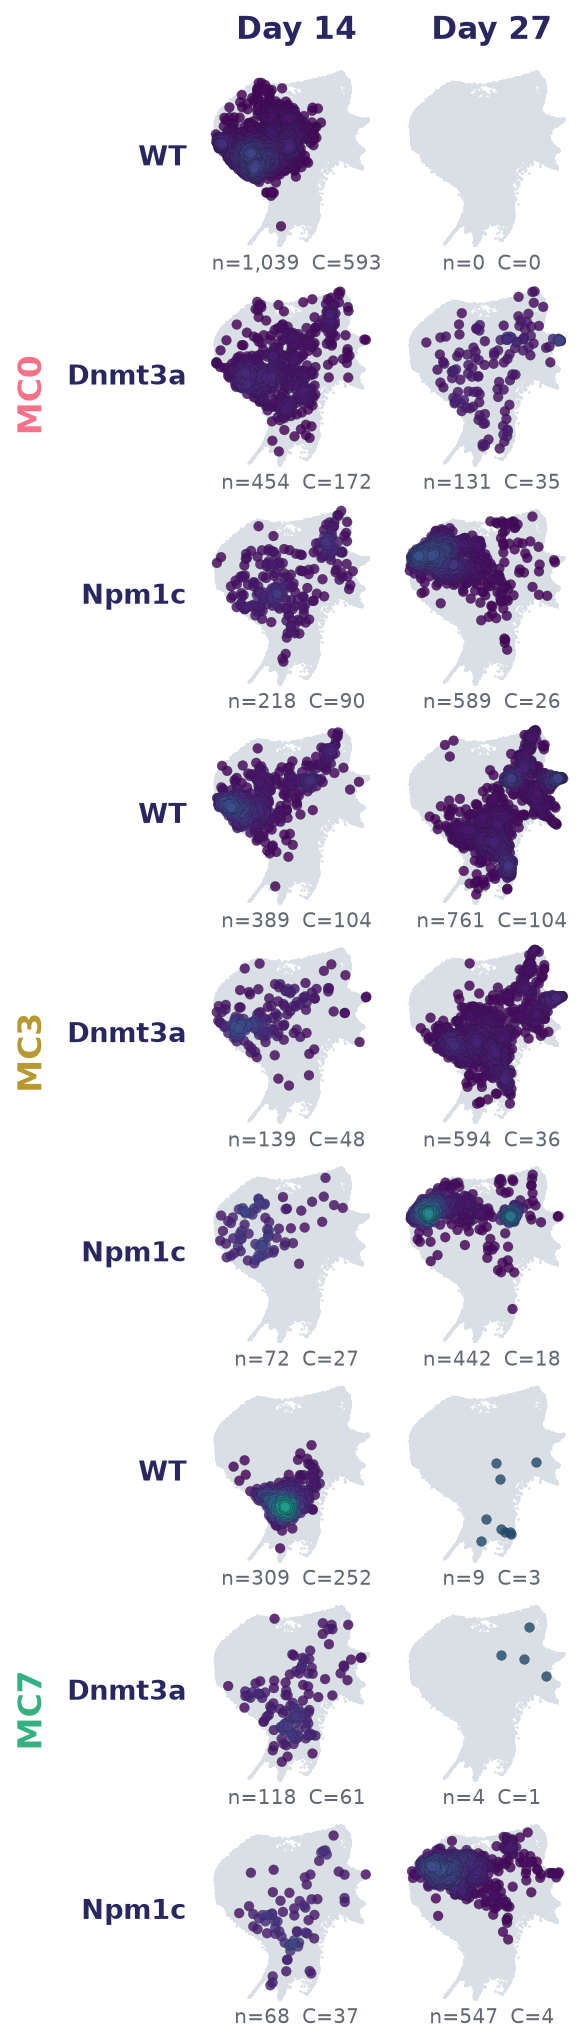

,stem,mc,arm,day,cells,families,representation,marker_ratio
0,figure_6c_condition_grid_flipped,0,WT,D14,1039,593,density_colored_points,0.06041
1,figure_6c_condition_grid_flipped,0,WT,D27,0,0,empty,0.06041
2,figure_6c_condition_grid_flipped,0,Dnmt3a,D14,454,172,density_colored_points,0.06041
3,figure_6c_condition_grid_flipped,0,Dnmt3a,D27,131,35,density_colored_points,0.06041
4,figure_6c_condition_grid_flipped,0,Npm1c,D14,218,90,density_colored_points,0.06041
5,figure_6c_condition_grid_flipped,0,Npm1c,D27,589,26,density_colored_points,0.06041
6,figure_6c_condition_grid_flipped,3,WT,D14,389,104,density_colored_points,0.06041
7,figure_6c_condition_grid_flipped,3,WT,D27,761,104,density_colored_points,0.06041
8,figure_6c_condition_grid_flipped,3,Dnmt3a,D14,139,48,density_colored_points,0.06041
9,figure_6c_condition_grid_flipped,3,Dnmt3a,D27,594,36,density_colored_points,0.06041


/path/to/ChronoClone/reference_workspace/Figure/singh_condition_grid_flipped_20261021/panels/figure_6c_condition_grid_flipped.svg 4d5a0ed74aa8c66ce801b070c38659a510a96a4c28fe4633ebe07d6642a816d5
figure size (in): 3.6799999999999997 12.799999999999999


In [5]:

# One flipped condition grid: days in columns, metaclone x arm in rows. No colour bar; the key is its own plot below.
stem='figure_6c_condition_grid_flipped'
metaclones=[0,3,7];arms=['WT','Dnmt3a','Npm1c'];days=['D14','D27']
rows=[(mc,arm) for mc in metaclones for arm in arms]
nc=len(days);nr=len(rows)
previous_figures=set(plt.get_fignums())
# Explicit geometry in inches: fixed axes size and pitch, so every map is drawn at the same scale.
MC_LABEL=0.34;ARM_LABEL=0.82;AXES=1.15;COL_PITCH=1.22;SUPPORT=0.17;ROW_PITCH=AXES+SUPPORT+0.05;HEADER=0.42
fw=MC_LABEL+ARM_LABEL+COL_PITCH*nc+0.08;fh=HEADER+ROW_PITCH*nr+0.05
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];support_records=[]
for j,day in enumerate(days):
    labels.append(fig.text((MC_LABEL+ARM_LABEL+COL_PITCH*(j+.5))/fw,1-0.10/fh,'Day '+day[1:],
                           ha='center',va='top',fontsize=14,fontweight='bold',color='#29275f'))
for i,(mc,arm) in enumerate(rows):
    bottom=fh-HEADER-ROW_PITCH*(i+1)+SUPPORT+0.05
    labels.append(fig.text((MC_LABEL+ARM_LABEL-0.08)/fw,(bottom+AXES/2)/fh,arm,ha='right',va='center',
                           fontsize=12,fontweight='bold',color='#29275f'))
    for j,day in enumerate(days):
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(MC_LABEL+ARM_LABEL+COL_PITCH*j)/fw,bottom/fh,AXES/fw,AXES/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((MC_LABEL+ARM_LABEL+COL_PITCH*(j+.5))/fw,(bottom-.025)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=9,color='#626972'))
        support_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt})
# One metaclone label per group of three arm rows, rotated at the left edge.
for g,mc in enumerate(metaclones):
    top=fh-HEADER-ROW_PITCH*(3*g);low=fh-HEADER-ROW_PITCH*(3*g+3)
    labels.append(fig.text(0.12/fw,(low+top)/2/fh,f'MC{mc}',ha='center',va='center',rotation=90,
                           fontsize=15,fontweight='bold',color=MC_LABEL_COLORS[mc]))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
svg.parent.mkdir(parents=True,exist_ok=True)
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
support=pd.DataFrame(support_records)
support.to_csv(OUT/'tables'/f'{stem}_support.csv',index=False)
display(support)
print(svg,sha256(svg));print('figure size (in):',fw,fh)


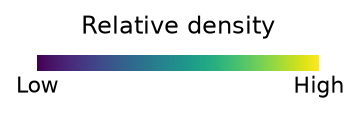

/path/to/ChronoClone/reference_workspace/Figure/singh_condition_grid_flipped_20261021/panels/figure_6c_density_key_horizontal.svg c9cda4fcb0ff5d255b82fcb68a64bce1bf519550f6d59a325471e158594a57c1 scale 0 to 0.34375069516975765


In [6]:

# The colour key alone, horizontal: same common density scale (DENSITY_NORM) as every map in the grid above.
stem='figure_6c_density_key_horizontal'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(2.2,0.62),dpi=160,facecolor='white')
bar=fig.add_axes([0.10,0.30,0.80,0.16])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar,orientation='horizontal')
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=2)
cb.outline.set_visible(False)
fig.text(0.5,0.62,'Relative density',fontsize=11,ha='center',va='bottom')
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
print(svg,sha256(svg),'scale 0 to',DENSITY_MAX)
